In [0]:
%pip install lifelines 

Looking in indexes: [REDACTED]
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for autograd-gamma: filename=autograd_gamma-0.5.0-py3-none-any.whl size=4119 sha256=8702e3f792af46b401d4e62f588554e2aeefe9517e49050278d5c4a9bf9e388c
  Stored in directory: /home/spark-a2ab4a5a-f250-47c2-9617-b7/.cache/pip/wheels/64/a2/a1/d7253b3fe88c7038ec3ef6a2cb2cedbf927b138b8077301f4d
Successfully built autograd-gamma
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [lifelines]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:

import numpy as np
import pandas as pd
from pyspark.sql import functions as F
from lifelines import CoxPHFitter

df = spark.table("workspace.default.freddie_model_split")

cols = [
    "time_months", "event_type",
    "fico", "orig_ltv",
    "orig_interest_rate", "log_orig_upb",
    "num_borrowers", "relief_refinance_flag"
]

train_pd = df.filter(F.col("split") == "train").select(*cols).toPandas()
val_pd = df.filter(F.col("split") == "validation").select(*cols).toPandas()

# Training-only imputation
fico_median = train_pd["fico"].median()

x_cols = [
    "fico_per_20", "ltv_per_10",
    "orig_interest_rate", "log_orig_upb",
    "num_borrowers", "relief_refinance"
]

for d in [train_pd, val_pd]:
    d["fico"] = d["fico"].fillna(fico_median)
    d["fico_per_20"] = d["fico"] / 20
    d["ltv_per_10"] = d["orig_ltv"] / 10
    d["relief_refinance"] = (
        d["relief_refinance_flag"] == "Y"
    ).astype(int)

print("Train:", len(train_pd))
print("Validation:", len(val_pd))
print("Missing predictors:", train_pd[x_cols].isna().sum().sum())


Train: 34975
Validation: 7495
Missing predictors: 0


In [0]:

# Cause 1: First 90+ DPD
train_1 = train_pd[x_cols + ["time_months"]].copy()
train_1["event"] = (train_pd["event_type"] == 1).astype(int)

# Cause 2: Payoff or other termination
train_2 = train_pd[x_cols + ["time_months"]].copy()
train_2["event"] = train_pd["event_type"].isin([2, 3]).astype(int)

cox_dpd = CoxPHFitter(penalizer=0.01)
cox_term = CoxPHFitter(penalizer=0.01)

cox_dpd.fit(
    train_1,
    duration_col="time_months",
    event_col="event"
)

cox_term.fit(
    train_2,
    duration_col="time_months",
    event_col="event"
)

print("90+ DPD events:", train_1["event"].sum())
print("Termination events:", train_2["event"].sum())

display(
    pd.DataFrame({
        "dpd_HR": cox_dpd.hazard_ratios_,
        "termination_HR": cox_term.hazard_ratios_
    })
)


90+ DPD events: 2048
Termination events: 25347


dpd_HR,termination_HR
0.8154658280708901,1.0146298127517257
1.0774397781243747,1.0233151601767216
1.5873233414442267,1.3453669529739263
1.575284524594241,1.548801072973998
0.6092302950946599,1.0416772608471765
0.9310466472438887,0.6965691522448982


In [0]:

months = np.arange(1, 37)
X_val = val_pd[x_cols]

# Predicted cumulative cause-specific hazards
H1 = cox_dpd.predict_cumulative_hazard(
    X_val, times=months
).to_numpy()

H2 = cox_term.predict_cumulative_hazard(
    X_val, times=months
).to_numpy()

# Monthly cumulative-hazard increments
dH1 = np.diff(
    np.vstack([np.zeros((1, H1.shape[1])), H1]),
    axis=0
)

dH2 = np.diff(
    np.vstack([np.zeros((1, H2.shape[1])), H2]),
    axis=0
)

# Piecewise-constant hazard approximation within each month
S = np.ones(len(val_pd))
CIF = np.zeros(len(val_pd))
predictions = {}

for i, month in enumerate(months):
    total = dH1[i] + dH2[i]

    p_exit = -np.expm1(-total)

    frac_dpd = np.divide(
        dH1[i], total,
        out=np.zeros_like(total),
        where=total > 0
    )

    CIF += S * p_exit * frac_dpd
    S *= np.exp(-total)

    if month in [12, 24, 36]:
        predictions[month] = CIF.copy()

# QC: valid probabilities and nondecreasing CIF
assert np.all((predictions[36] >= 0) &
              (predictions[36] <= 1))
assert np.all(predictions[12] <= predictions[24] + 1e-10)
assert np.all(predictions[24] <= predictions[36] + 1e-10)

print("Personalized CIF predictions computed!")


Personalized CIF predictions computed!


In [0]:

summary = []

for h in [12, 24, 36]:
    observed = (
        (val_pd["event_type"] == 1) &
        (val_pd["time_months"] <= h)
    ).astype(int)

    summary.append({
        "horizon": h,
        "n_events": int(observed.sum()),
        "observed_risk_pct": 100 * observed.mean(),
        "predicted_risk_pct": 100 * predictions[h].mean(),
        "difference_pp": 100 * (
            predictions[h].mean() - observed.mean()
        )
    })

display(pd.DataFrame(summary).round(3))


horizon,n_events,observed_risk_pct,predicted_risk_pct,difference_pp
12,24,0.32,0.419,0.099
24,64,0.854,0.837,-0.017
36,253,3.376,3.31,-0.066


In [0]:

from sklearn.metrics import (
    roc_auc_score,
    brier_score_loss
)
import pandas as pd
import numpy as np

# 36-month observed outcome
y36 = (
    (val_pd["event_type"] == 1) &
    (val_pd["time_months"] <= 36)
).astype(int).to_numpy()

# Personalized 36-month cumulative incidence
risk36 = predictions[36]

# Check administrative censoring before horizon
early_censor = (
    (val_pd["event_type"] == 0) &
    (val_pd["time_months"] <= 36)
).sum()

assert early_censor == 0
assert len(y36) == len(risk36)

cal = pd.DataFrame({
    "observed": y36,
    "predicted": risk36
})

# Divide validation loans into risk deciles
cal["decile"] = pd.qcut(
    cal["predicted"],
    q=10,
    labels=False,
    duplicates="drop"
) + 1

cal_summary = (
    cal.groupby("decile")
    .agg(
        n_loans=("observed", "size"),
        n_events=("observed", "sum"),
        observed_risk=("observed", "mean"),
        predicted_risk=("predicted", "mean")
    )
    .reset_index()
)

cal_summary["observed_pct"] = (
    100 * cal_summary["observed_risk"]
)

cal_summary["predicted_pct"] = (
    100 * cal_summary["predicted_risk"]
)

display(cal_summary.round(3))


decile,n_loans,n_events,observed_risk,predicted_risk,observed_pct,predicted_pct
1,750,6,0.008,0.009,0.8,0.934
2,749,12,0.016,0.014,1.602,1.398
3,750,6,0.008,0.017,0.8,1.719
4,749,15,0.02,0.021,2.003,2.057
5,750,14,0.019,0.024,1.867,2.433
6,749,20,0.027,0.029,2.67,2.871
7,749,19,0.025,0.034,2.537,3.41
8,750,37,0.049,0.042,4.933,4.157
9,749,48,0.064,0.054,6.409,5.376
10,750,76,0.101,0.087,10.133,8.74


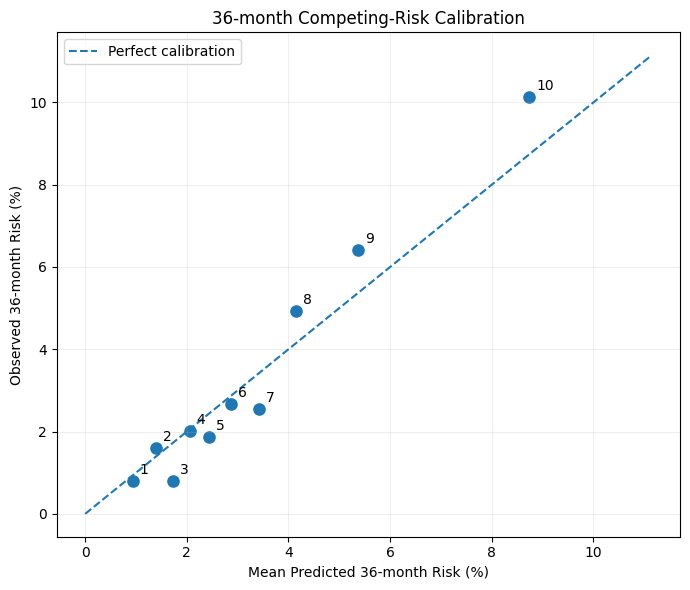

In [0]:

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

plt.scatter(
    cal_summary["predicted_pct"],
    cal_summary["observed_pct"],
    s=65
)

for _, r in cal_summary.iterrows():
    plt.annotate(
        str(int(r["decile"])),
        (
            r["predicted_pct"],
            r["observed_pct"]
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )

lim = 1.1 * max(
    cal_summary["predicted_pct"].max(),
    cal_summary["observed_pct"].max()
)

plt.plot(
    [0, lim], [0, lim],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean Predicted 36-month Risk (%)")
plt.ylabel("Observed 36-month Risk (%)")
plt.title("36-month Competing-Risk Calibration")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [0]:

# Model performance
auc36 = roc_auc_score(y36, risk36)
brier36 = brier_score_loss(y36, risk36)

# Constant-risk reference model
base_risk = np.repeat(y36.mean(), len(y36))

baseline_brier = brier_score_loss(
    y36, base_risk
)

print(f"36-month CIF AUC: {auc36:.4f}")
print(f"36-month Brier Score: {brier36:.5f}")
print(f"Constant-risk Brier: {baseline_brier:.5f}")
print(
    "Brier skill score:",
    round(1 - brier36 / baseline_brier, 4)
)


36-month CIF AUC: 0.7195
36-month Brier Score: 0.03186
Constant-risk Brier: 0.03262
Brier skill score: 0.0233


In [0]:

import numpy as np
import pandas as pd

# Quantify calibration in the highest-risk deciles
high_risk = cal[cal["decile"] >= 8]

print("=== Highest 30% Predicted Risk ===")
print("Loans:", len(high_risk))
print("Observed events:", high_risk["observed"].sum())
print(
    "Mean predicted risk:",
    f"{100 * high_risk['predicted'].mean():.2f}%"
)
print(
    "Observed risk:",
    f"{100 * high_risk['observed'].mean():.2f}%"
)

# Wilson 95% intervals for observed risk by decile
z = 1.96
n = cal_summary["n_loans"].to_numpy()
p = cal_summary["observed_risk"].to_numpy()

denom = 1 + z**2 / n
center = (p + z**2 / (2*n)) / denom
half = (
    z * np.sqrt(p*(1-p)/n + z**2/(4*n**2))
    / denom
)

cal_summary["observed_lower_95"] = 100 * (center-half)
cal_summary["observed_upper_95"] = 100 * (center+half)

display(cal_summary[[
    "decile", "n_loans", "n_events",
    "predicted_pct", "observed_pct",
    "observed_lower_95", "observed_upper_95"
]].round(2))


=== Highest 30% Predicted Risk ===
Loans: 2249
Observed events: 161
Mean predicted risk: 6.09%
Observed risk: 7.16%


decile,n_loans,n_events,predicted_pct,observed_pct,observed_lower_95,observed_upper_95
1,750,6,0.93,0.8,0.37,1.73
2,749,12,1.4,1.6,0.92,2.78
3,750,6,1.72,0.8,0.37,1.73
4,749,15,2.06,2.0,1.22,3.28
5,750,14,2.43,1.87,1.12,3.11
6,749,20,2.87,2.67,1.74,4.09
7,749,19,3.41,2.54,1.63,3.93
8,750,37,4.16,4.93,3.6,6.73
9,749,48,5.38,6.41,4.87,8.39
10,750,76,8.74,10.13,8.17,12.5


In [0]:



rng = np.random.default_rng(42)

obs = high_risk["observed"].to_numpy()
pred = high_risk["predicted"].to_numpy()

# Observed minus predicted risk
diff = obs - pred

B = 3000
boot_diff = np.empty(B)

for b in range(B):
    idx = rng.integers(0, len(diff), len(diff))
    boot_diff[b] = diff[idx].mean()

ci = np.percentile(boot_diff, [2.5, 97.5])

print(f"Observed - Predicted: {100*diff.mean():.3f} pp")
print(
    f"Bootstrap 95% CI: "
    f"[{100*ci[0]:.3f}, {100*ci[1]:.3f}] pp"
)

# Risk concentration
total_events = int(y36.sum())
captured_events = int(obs.sum())

print(
    f"Event capture: "
    f"{captured_events / total_events:.1%}"
)

print(
    f"Risk lift: "
    f"{obs.mean() / y36.mean():.2f}x"
)


Observed - Predicted: 1.067 pp
Bootstrap 95% CI: [0.060, 2.224] pp
Event capture: 63.6%
Risk lift: 2.12x


In [0]:
%pip install xgboost

Looking in indexes: [REDACTED]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.2/57.2 MB 140.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 305.1/305.1 MB 142.9 MB/s  0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [xgboost]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:

import xgboost as xgb


X_train = train_pd[x_cols]
X_val = val_pd[x_cols]

params = dict(
    objective="survival:cox",
    eval_metric="cox-nloglik",
    tree_method="hist",
    n_estimators=800,
    learning_rate=0.03,
    max_depth=2,
    min_child_weight=20,
    subsample=0.8,
    colsample_bytree=0.9,
    reg_lambda=10,
    early_stopping_rounds=40,
    random_state=42,
    n_jobs=4
)

def make_survival_labels(data, cause):
    event = (
        data["event_type"] == 1
        if cause == 1
        else data["event_type"].isin([2, 3])
    )
    time = data["time_months"].to_numpy()
    return np.where(event, time, -time).astype(float)

xgb_dpd = xgb.XGBRegressor(**params)
xgb_term = xgb.XGBRegressor(**params)

for model, cause in [(xgb_dpd, 1), (xgb_term, 2)]:
    model.fit(
        X_train,
        make_survival_labels(train_pd, cause),
        eval_set=[(
            X_val,
            make_survival_labels(val_pd, cause)
        )],
        verbose=False
    )
    print(
        f"Cause {cause}: "
        f"best iteration = {model.best_iteration}"
    )


Cause 1: best iteration = 437
Cause 2: best iteration = 387


In [0]:

months = np.arange(1, 37)

def breslow_increments(model, X, data, cause, max_month=36):
    # XGBoost survival:cox returns relative hazard
    scores = np.asarray(model.predict(X), dtype=float)
    times = data["time_months"].to_numpy().astype(int)

    event = (
        data["event_type"].to_numpy() == 1
        if cause == 1
        else np.isin(data["event_type"].to_numpy(), [2, 3])
    )

    assert np.all(times >= 1)
    assert np.all(np.isfinite(scores) & (scores > 0))

    # Weighted risk set at each month: T >= month
    max_t = max(int(times.max()), max_month)

    weighted_exits = np.bincount(
        times, weights=scores, minlength=max_t + 2
    )
    risk_sum = np.cumsum(weighted_exits[::-1])[::-1]

    # Number of cause-specific events per month
    events = np.bincount(
        times[event], minlength=max_t + 2
    )

    # Breslow cumulative baseline hazard increments
    return np.divide(
        events[1:max_month + 1],
        risk_sum[1:max_month + 1],
        out=np.zeros(max_month),
        where=risk_sum[1:max_month + 1] > 0
    )

base1 = breslow_increments(
    xgb_dpd, X_train, train_pd, cause=1
)
base2 = breslow_increments(
    xgb_term, X_train, train_pd, cause=2
)

risk1 = np.asarray(xgb_dpd.predict(X_val), dtype=float)
risk2 = np.asarray(xgb_term.predict(X_val), dtype=float)

# Individual monthly cumulative-hazard increments
dH1 = base1[:, None] * risk1[None, :]
dH2 = base2[:, None] * risk2[None, :]

S = np.ones(len(X_val))
F1 = np.zeros(len(X_val))

xgb_cif = {}

for i, month in enumerate(months):
    total = dH1[i] + dH2[i]

    p_exit = -np.expm1(-total)

    frac1 = np.divide(
        dH1[i], total,
        out=np.zeros_like(total),
        where=total > 0
    )

    F1 += S * p_exit * frac1
    S *= np.exp(-total)

    if month in [12, 24, 36]:
        xgb_cif[month] = F1.copy()

assert np.all((xgb_cif[36] >= 0) & (xgb_cif[36] <= 1))
assert np.all(xgb_cif[12] <= xgb_cif[24] + 1e-10)
assert np.all(xgb_cif[24] <= xgb_cif[36] + 1e-10)

print("XGBoost personalized CIF computed!")


XGBoost personalized CIF computed!


In [0]:

from sklearn.metrics import roc_auc_score, brier_score_loss

results = []

for h in [12, 24, 36]:
    y = (
        (val_pd["event_type"] == 1) &
        (val_pd["time_months"] <= h)
    ).astype(int).to_numpy()

    early_censor = (
        (val_pd["event_type"] == 0) &
        (val_pd["time_months"] <= h)
    ).sum()

    assert early_censor == 0

    for name, p in [
        ("Cox CIF", predictions[h]),
        ("XGBoost CIF", xgb_cif[h])
    ]:
        results.append({
            "horizon": h,
            "model": name,
            "auc": roc_auc_score(y, p),
            "brier": brier_score_loss(y, p),
            "observed_pct": 100 * y.mean(),
            "predicted_pct": 100 * p.mean(),
            "bias_pp": 100 * (p.mean() - y.mean())
        })

comparison = pd.DataFrame(results)

display(comparison.round(4))


horizon,model,auc,brier,observed_pct,predicted_pct,bias_pp
12,Cox CIF,0.7455,0.0032,0.3202,0.4188,0.0986
12,XGBoost CIF,0.7482,0.0032,0.3202,0.4191,0.0989
24,Cox CIF,0.7434,0.0084,0.8539,0.8366,-0.0173
24,XGBoost CIF,0.7573,0.0084,0.8539,0.837,-0.0169
36,Cox CIF,0.7195,0.0319,3.3756,3.3097,-0.0659
36,XGBoost CIF,0.7272,0.0317,3.3756,3.3126,-0.0629


In [0]:



# Observed 36-month outcome
y36 = (
    (val_pd["event_type"] == 1) &
    (val_pd["time_months"] <= 36)
).astype(int).to_numpy()

model_predictions = {
    "Cox CIF": np.asarray(predictions[36]),
    "XGBoost CIF": np.asarray(xgb_cif[36])
}

n_top = int(np.ceil(len(y36) * 0.30))
total_events = y36.sum()

results = []

for name, risk in model_predictions.items():

    # Select the highest-risk 30%
    top_idx = np.argsort(risk, kind="stable")[-n_top:]

    observed = y36[top_idx]
    predicted = risk[top_idx]

    results.append({
        "model": name,
        "n_loans": len(top_idx),
        "events": int(observed.sum()),
        "predicted_pct": 100 * predicted.mean(),
        "observed_pct": 100 * observed.mean(),
        "underprediction_pp": 100 * (
            observed.mean() - predicted.mean()
        ),
        "event_capture_pct": 100 * (
            observed.sum() / total_events
        ),
        "risk_lift": (
            observed.mean() / y36.mean()
        )
    })

high_risk_comparison = pd.DataFrame(results)

display(high_risk_comparison.round(3))


model,n_loans,events,predicted_pct,observed_pct,underprediction_pp,event_capture_pct,risk_lift
Cox CIF,2249,161,6.091,7.159,1.067,63.636,2.121
XGBoost CIF,2249,162,6.742,7.203,0.461,64.032,2.134


In [0]:

from sklearn.metrics import roc_auc_score, brier_score_loss

rng = np.random.default_rng(42)

p_cox = model_predictions["Cox CIF"]
p_xgb = model_predictions["XGBoost CIF"]

B = 1500
auc_diff = []
brier_diff = []

for b in range(B):
    idx = rng.integers(0, len(y36), len(y36))

    y = y36[idx]

    if len(np.unique(y)) < 2:
        continue

    cox = p_cox[idx]
    xgb = p_xgb[idx]

    auc_diff.append(
        roc_auc_score(y, xgb) -
        roc_auc_score(y, cox)
    )

    # Positive means XGBoost has a lower Brier score
    brier_diff.append(
        brier_score_loss(y, cox) -
        brier_score_loss(y, xgb)
    )

for name, values in [
    ("AUC improvement (XGB - Cox)", auc_diff),
    ("Brier reduction (Cox - XGB)", brier_diff)
]:
    lo, hi = np.percentile(values, [2.5, 97.5])

    print(name)
    print(f"Mean: {np.mean(values):.5f}")
    print(f"95% CI: [{lo:.5f}, {hi:.5f}]")
    print()


AUC improvement (XGB - Cox)
Mean: 0.00776
95% CI: [-0.00207, 0.01690]

Brier reduction (Cox - XGB)
Mean: 0.00013
95% CI: [0.00000, 0.00027]



**Final Test — Cox vs. XGBoost CIF**

In [0]:



# Read untouched test set
df = spark.table("workspace.default.freddie_model_split")

test_pd = (
    df.filter(F.col("split") == "test")
      .select(*cols)
      .toPandas()
)

# Apply training preprocessing only
test_pd["fico"] = test_pd["fico"].fillna(fico_median)
test_pd["fico_per_20"] = test_pd["fico"] / 20
test_pd["ltv_per_10"] = test_pd["orig_ltv"] / 10
test_pd["relief_refinance"] = (
    test_pd["relief_refinance_flag"] == "Y"
).astype(int)

X_test = test_pd[x_cols]

assert len(test_pd) == 7498
assert X_test.isna().sum().sum() == 0

# Confirm outcomes are known at each horizon
for h in [12, 24, 36]:
    early_censor = (
        (test_pd["event_type"] == 0) &
        (test_pd["time_months"] <= h)
    ).sum()

    assert early_censor == 0, (
        f"{h}m has {early_censor} early censored loans"
    )

# CIF calculation shared by both models
def compute_cif(dH1, dH2):
    n = dH1.shape[1]
    S = np.ones(n)
    F1 = np.zeros(n)
    output = {}

    for i in range(dH1.shape[0]):
        total = dH1[i] + dH2[i]

        p_exit = -np.expm1(-total)
        fraction = np.divide(
            dH1[i], total,
            out=np.zeros_like(total),
            where=total > 0
        )

        F1 += S * p_exit * fraction
        S *= np.exp(-total)

        if i + 1 in [12, 24, 36]:
            output[i + 1] = F1.copy()

    return output

# Cox: predicted cause-specific cumulative hazards
months = np.arange(1, 37)

H1 = cox_dpd.predict_cumulative_hazard(
    X_test, times=months
).to_numpy()

H2 = cox_term.predict_cumulative_hazard(
    X_test, times=months
).to_numpy()

dH1 = np.diff(
    np.vstack([np.zeros((1, len(test_pd))), H1]),
    axis=0
)
dH2 = np.diff(
    np.vstack([np.zeros((1, len(test_pd))), H2]),
    axis=0
)

cox_test_cif = compute_cif(dH1, dH2)

# XGBoost: use frozen training baseline hazards
risk1 = np.asarray(xgb_dpd.predict(X_test))
risk2 = np.asarray(xgb_term.predict(X_test))

xgb_test_cif = compute_cif(
    base1[:, None] * risk1[None, :],
    base2[:, None] * risk2[None, :]
)

# Final performance comparison
test_results = []

for h in [12, 24, 36]:
    y = (
        (test_pd["event_type"] == 1) &
        (test_pd["time_months"] <= h)
    ).astype(int).to_numpy()

    for name, p in [
        ("Cox CIF", cox_test_cif[h]),
        ("XGBoost CIF", xgb_test_cif[h])
    ]:
        test_results.append({
            "horizon": h,
            "model": name,
            "n_events": int(y.sum()),
            "auc": roc_auc_score(y, p),
            "brier": brier_score_loss(y, p),
            "observed_pct": 100 * y.mean(),
            "predicted_pct": 100 * p.mean(),
            "bias_pp": 100 * (p.mean() - y.mean())
        })

test_comparison = pd.DataFrame(test_results)

display(test_comparison.round(4))


horizon,model,n_events,auc,brier,observed_pct,predicted_pct,bias_pp
12,Cox CIF,23,0.7913,0.003,0.3067,0.4166,0.1098
12,XGBoost CIF,23,0.769,0.003,0.3067,0.4158,0.1091
24,Cox CIF,60,0.7954,0.0079,0.8002,0.8324,0.0322
24,XGBoost CIF,60,0.7851,0.0079,0.8002,0.8307,0.0304
36,Cox CIF,275,0.7074,0.0346,3.6676,3.2987,-0.369
36,XGBoost CIF,275,0.7094,0.0346,3.6676,3.2898,-0.3778


**Final Test — Top 30% Risk Capture**

In [0]:

y36_test = (
    (test_pd["event_type"] == 1) &
    (test_pd["time_months"] <= 36)
).astype(int).to_numpy()

n_top = int(np.ceil(len(y36_test) * 0.30))

rows = []

for name, risk in [
    ("Cox CIF", cox_test_cif[36]),
    ("XGBoost CIF", xgb_test_cif[36])
]:
    idx = np.argsort(risk, kind="stable")[-n_top:]

    rows.append({
        "model": name,
        "n_loans": len(idx),
        "events": int(y36_test[idx].sum()),
        "capture_pct": 100 * (
            y36_test[idx].sum() / y36_test.sum()
        ),
        "predicted_pct": 100 * risk[idx].mean(),
        "observed_pct": 100 * y36_test[idx].mean()
    })

display(pd.DataFrame(rows).round(3))


model,n_loans,events,capture_pct,predicted_pct,observed_pct
Cox CIF,2250,160,58.182,6.058,7.111
XGBoost CIF,2250,160,58.182,6.676,7.111


In [0]:

models = {
    "Cox CIF": cox_test_cif,
    "XGBoost CIF": xgb_test_cif
}

n = len(test_pd)
n_top = int(np.ceil(n * 0.30))
records = []

for model_name, cif in models.items():
    d = test_pd[[
        "time_months", "event_type",
        "fico", "orig_ltv",
        "orig_interest_rate", "num_borrowers"
    ]].reset_index(drop=True).copy()

    d["model"] = model_name

    for h in [12, 24, 36]:
        d[f"risk_{h}"] = cif[h]
        d[f"event_{h}"] = (
            (d["event_type"] == 1) &
            (d["time_months"] <= h)
        ).astype(int)

    risk = np.asarray(cif[36])

    # Rank mortgages into 10 risk groups
    d["risk_decile"] = (
        pd.qcut(
            pd.Series(risk).rank(method="first"),
            q=10,
            labels=False
        ).astype(int) + 1
    )

    # Mark highest-risk 30%
    top_idx = np.argsort(
        risk, kind="stable"
    )[-n_top:]

    d["top_30pct"] = False
    d.loc[top_idx, "top_30pct"] = True

    records.append(d)

dashboard_pd = pd.concat(
    records, ignore_index=True
)

# Save predictions to a Delta table
(
    spark.createDataFrame(dashboard_pd)
    .write.mode("overwrite")
    .option("overwriteSchema", "true")
    .saveAsTable(
        "workspace.default.freddie_dashboard_predictions"
    )
)

# Save final test performance metrics
(
    spark.createDataFrame(test_comparison)
    .write.mode("overwrite")
    .option("overwriteSchema", "true")
    .saveAsTable(
        "workspace.default.freddie_dashboard_metrics"
    )
)

print("Dashboard tables saved!")
print("Prediction rows:", len(dashboard_pd))
display(
    spark.table(
        "workspace.default.freddie_dashboard_metrics"
    )
)


Dashboard tables saved!
Prediction rows: 14996


horizon,model,n_events,auc,brier,observed_pct,predicted_pct,bias_pp
12,Cox CIF,23,0.791345063254326,0.003044121998999861,0.3067484662576687,0.416562702938749,0.10981423668108026
12,XGBoost CIF,23,0.7689922931510833,0.0030479286407285714,0.3067484662576687,0.4158474350694971,0.10909896881182839
24,Cox CIF,60,0.7953840638164382,0.007855149963267848,0.8002133902373967,0.832431246698718,0.03221785646132132
24,XGBoost CIF,60,0.7850609482835889,0.007853970067548177,0.8002133902373967,0.8306604165229569,0.030447026285560126
36,Cox CIF,275,0.7073545366443054,0.034622310995092526,3.6676447052547347,3.298676580279991,-0.36896812497474385
36,XGBoost CIF,275,0.7093793815211509,0.03456444784525754,3.6676447052547347,3.289813658453542,-0.3778310468011928
